# Part A: Data Cleaning & Preparation

In [31]:
#Cell 1 — Imports & Global Settings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error

import datetime as dt

pd.set_option('display.float_format', '{:,.2f}'.format)

# Helper for seasons
def month_to_season(m):
    if m in [12, 1, 2]:
        return 'Winter'
    elif m in [3, 4, 5]:
        return 'Spring'
    elif m in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'
    
current_year = dt.datetime.now().year

In [32]:
# Cell 2 — Load IMDB Dataset

# Adjust the path if needed, e.g. './IMDB_Movies.csv'
df = pd.read_csv("IMDB_Movies.csv")

print("Shape:", df.shape)
df.head()


Shape: (5438, 15)


,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,Trojan War,PG-13,Comedy,1997,"October 1, 1997 (Brazil)",5.70,5800,George Huang,Andy Burg,Will Friedle,United States,15000000,309,Daybreak,85.00
1,Madadayo,NaN,Drama,1993,"April 17, 1993 (Japan)",7.30,5100,Akira Kurosawa,Ishirô Honda,Tatsuo Matsumura,Japan,11900000,596,DENTSU Music And Entertainment,134.00
2,Parasite,R,Horror,1982,"March 12, 1982 (United States)",3.90,2300,Charles Band,Alan J. Adler,Robert Glaudini,United States,800000,2270,Embassy Pictures,85.00
3,Ginger Snaps,Not Rated,Drama,2000,"May 11, 2001 (Canada)",6.80,43000,John Fawcett,Karen Walton,Emily Perkins,Canada,5000000,2554,Copperheart Entertainment,108.00
4,Philadelphia Experiment II,PG-13,Action,1993,"June 4, 1994 (South Korea)",4.50,1900,Stephen Cornwell,Wallace C. Bennett,Brad Johnson,United States,5000000,2970,Trimark Pictures,97.00


In [33]:
# Cell 3 — Basic Info

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5438 entries, 0 to 5437
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      5438 non-null   object 
 1   rating    5426 non-null   object 
 2   genre     5438 non-null   object 
 3   year      5438 non-null   int64  
 4   released  5438 non-null   object 
 5   score     5438 non-null   float64
 6   votes     5438 non-null   int64  
 7   director  5438 non-null   object 
 8   writer    5438 non-null   object 
 9   star      5438 non-null   object 
 10  country   5437 non-null   object 
 11  budget    5438 non-null   int64  
 12  gross     5438 non-null   int64  
 13  company   5436 non-null   object 
 14  runtime   5437 non-null   float64
dtypes: float64(2), int64(4), object(9)
memory usage: 637.4+ KB


In [34]:
# Cell 4 — Parse 'released' column and Drop Obvious Bad Rows

# 1. Extract only the date portion before "(" and convert to datetime
before = df.shape[0]
df['release_date'] = df['released'].str.extract(r'^(.*?)(?:\s*\()')[0]
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
after = df.shape[0]
print(f"[Step 1] Parsed 'released' → 'release_date' | Rows affected: {before - after}")

# 2. Drop rows where release_date could not be parsed
before = df.shape[0]
df = df.dropna(subset=['release_date'])
after = df.shape[0]
print(f"[Step 2] Dropped rows with invalid release_date: {before - after} removed "
      f"(from {before} to {after})")

# 3. Drop rows with missing critical fields
critical_cols = [
    'name', 'rating', 'genre', 'year', 'release_date',
    'score', 'votes', 'budget', 'gross', 'company',
    'runtime', 'country'
]

before = df.shape[0]
df = df.dropna(subset=critical_cols)
after = df.shape[0]
print(f"[Step 3] Dropped rows missing critical fields: {before - after} removed "
      f"(from {before} to {after})")

# 4. Keep only positive budget & gross values
before = df.shape[0]
df = df[(df['budget'] > 0) & (df['gross'] > 0)]
after = df.shape[0]
print(f"[Step 4] Removed rows with non-positive budget/gross: {before - after} removed "
      f"(from {before} to {after})")

print("\nFinal shape after initial cleaning:", df.shape)

df.head()


[Step 1] Parsed 'released' → 'release_date' | Rows affected: 0
[Step 2] Dropped rows with invalid release_date: 14 removed (from 5438 to 5424)
[Step 3] Dropped rows missing critical fields: 15 removed (from 5424 to 5409)
[Step 4] Removed rows with non-positive budget/gross: 0 removed (from 5409 to 5409)

Final shape after initial cleaning: (5409, 16)


,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime,release_date
0,Trojan War,PG-13,Comedy,1997,"October 1, 1997 (Brazil)",5.70,5800,George Huang,Andy Burg,Will Friedle,United States,15000000,309,Daybreak,85.00,1997-10-01
2,Parasite,R,Horror,1982,"March 12, 1982 (United States)",3.90,2300,Charles Band,Alan J. Adler,Robert Glaudini,United States,800000,2270,Embassy Pictures,85.00,1982-03-12
3,Ginger Snaps,Not Rated,Drama,2000,"May 11, 2001 (Canada)",6.80,43000,John Fawcett,Karen Walton,Emily Perkins,Canada,5000000,2554,Copperheart Entertainment,108.00,2001-05-11
4,Philadelphia Experiment II,PG-13,Action,1993,"June 4, 1994 (South Korea)",4.50,1900,Stephen Cornwell,Wallace C. Bennett,Brad Johnson,United States,5000000,2970,Trimark Pictures,97.00,1994-06-04
5,Tanner Hall,R,Drama,2009,"January 15, 2015 (Sweden)",5.80,3500,Francesca Gregorini,Tatiana von Fürstenberg,Rooney Mara,United States,3000000,5073,Two Prong Lesson,96.00,2015-01-15


In [35]:
# Cell 5 — Date-Based Features

df['release_year'] = df['release_date'].dt.year
df['release_month'] = df['release_date'].dt.month.astype(int)
df['release_day'] = df['release_date'].dt.day.astype(int)

df['release_season'] = df['release_month'].apply(month_to_season)

# release_day_bin: 1–5, 6–10, 11–15, 16–20, 21–25, 26–31
bins = [0, 5, 10, 15, 20, 25, 31]
labels = ['1-5', '6-10', '11-15', '16-20', '21-25', '26-31']

df['release_day_bin'] = pd.cut(
    df['release_day'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

df[['release_year', 'release_month', 'release_day', 'release_season', 'release_day_bin']].head()


,release_year,release_month,release_day,release_season,release_day_bin
0,1997,10,1,Fall,1-5
2,1982,3,12,Spring,11-15
3,2001,5,11,Spring,11-15
4,1994,6,4,Summer,1-5
5,2015,1,15,Winter,11-15


In [36]:
# Cell 6 — movie_name_length and years_since_production

df['movie_name_length'] = df['name'].astype(str).str.len()

# Years since production based on RELEASE YEAR (as required)
df['years_since_production'] = current_year - df['release_year']

df[['name', 'movie_name_length', 'years_since_production']].head()


,name,movie_name_length,years_since_production
0,Trojan War,10,28
2,Parasite,8,43
3,Ginger Snaps,12,24
4,Philadelphia Experiment II,26,31
5,Tanner Hall,11,10


In [37]:
# Cell 7 — budget_inflation_adjusted and profit

# Average annual inflation between 1980 and today: 3.09%
inflation_rate = 0.0309

# Use 'year' as production year for inflation adjustment
years_diff = current_year - df['year']
df['budget_inflation_adjusted'] = df['budget'] * ((1 + inflation_rate) ** years_diff)

# profit = gross - budget_inflation_adjusted
df['profit'] = df['gross'] - df['budget_inflation_adjusted']

df[['budget', 'budget_inflation_adjusted', 'gross', 'profit']].head()


,budget,budget_inflation_adjusted,gross,profit
0,15000000,"35,168,542.37",309,"-35,168,233.37"
2,800000,"2,960,746.27",2270,"-2,958,476.27"
3,5000000,"10,699,993.03",2554,"-10,697,439.03"
4,5000000,"13,240,344.11",2970,"-13,237,374.11"
5,3000000,"4,881,866.38",5073,"-4,876,793.38"


In [38]:
# Cell 8 — Remove Extreme Profit Outliers (IQR method) and Create df_clean

# 1. Compute profit
df['profit'] = df['gross'] - df['budget_inflation_adjusted']

# 2. Identify outliers using IQR
Q1 = df['profit'].quantile(0.25)
Q3 = df['profit'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Using IQR on profit to remove extreme financial outliers that could distort regression and ML models

# 3. Remove outliers with BEFORE/AFTER REPORTING
before = df.shape[0]
df_clean = df[(df['profit'] >= lower_bound) & (df['profit'] <= upper_bound)]
after = df_clean.shape[0]

print("Profit outlier removal using IQR:")
print(f" - Rows removed: {before - after}")
print(f" - Rows before:  {before}")
print(f" - Rows after:   {after}")

df_clean.head()

Profit outlier removal using IQR:
 - Rows removed: 640
 - Rows before:  5409
 - Rows after:   4769


,name,rating,genre,year,released,score,votes,director,writer,star,...,release_date,release_year,release_month,release_day,release_season,release_day_bin,movie_name_length,years_since_production,budget_inflation_adjusted,profit
0,Trojan War,PG-13,Comedy,1997,"October 1, 1997 (Brazil)",5.70,5800,George Huang,Andy Burg,Will Friedle,...,1997-10-01,1997,10,1,Fall,1-5,10,28,"35,168,542.37","-35,168,233.37"
2,Parasite,R,Horror,1982,"March 12, 1982 (United States)",3.90,2300,Charles Band,Alan J. Adler,Robert Glaudini,...,1982-03-12,1982,3,12,Spring,11-15,8,43,"2,960,746.27","-2,958,476.27"
3,Ginger Snaps,Not Rated,Drama,2000,"May 11, 2001 (Canada)",6.80,43000,John Fawcett,Karen Walton,Emily Perkins,...,2001-05-11,2001,5,11,Spring,11-15,12,24,"10,699,993.03","-10,697,439.03"
4,Philadelphia Experiment II,PG-13,Action,1993,"June 4, 1994 (South Korea)",4.50,1900,Stephen Cornwell,Wallace C. Bennett,Brad Johnson,...,1994-06-04,1994,6,4,Summer,1-5,26,31,"13,240,344.11","-13,237,374.11"
5,Tanner Hall,R,Drama,2009,"January 15, 2015 (Sweden)",5.80,3500,Francesca Gregorini,Tatiana von Fürstenberg,Rooney Mara,...,2015-01-15,2015,1,15,Winter,11-15,11,10,"4,881,866.38","-4,876,793.38"


In [39]:
# Cell 9 — Measurement Table (variable name & categorical/continuous)

measurement = []
for col in df_clean.columns:
    if pd.api.types.is_numeric_dtype(df_clean[col]):
        measurement.append('continuous')
    else:
        measurement.append('categorical')

measurement_df = pd.DataFrame({
    'Variable': df_clean.columns,
    'Measurement': measurement
})

measurement_df


,Variable,Measurement
0,name,categorical
1,rating,categorical
2,genre,categorical
3,year,continuous
4,released,categorical
5,score,continuous
6,votes,continuous
7,director,categorical
8,writer,categorical
9,star,categorical


In [40]:
# Cell 10 — Summary Statistics of Continuous Variables

continuous_vars = measurement_df[measurement_df['Measurement'] == 'continuous']['Variable'].tolist()

summary_stats = df_clean[continuous_vars].describe().T
summary_stats


,count,mean,std,min,25%,50%,75%,max
year,"4,769.00","2,000.94",10.46,"1,980.00","1,993.00","2,001.00","2,010.00","2,020.00"
score,"4,769.00",6.33,0.94,1.90,5.80,6.40,7.00,9.30
votes,"4,769.00","81,767.76","120,920.41",195.00,"16,000.00","44,000.00","100,000.00","2,400,000.00"
budget,"4,769.00","28,491,076.40","30,237,358.69","3,000.00","9,500,000.00","20,000,000.00","35,000,000.00","275,000,000.00"
gross,"4,769.00","55,568,051.92","67,257,303.40",309.00,"9,094,451.00","29,000,301.00","77,663,556.00","460,435,291.00"
runtime,"4,769.00",106.79,16.99,63.00,95.00,104.00,116.00,271.00
release_year,"4,769.00","2,001.10",10.48,"1,980.00","1,993.00","2,002.00","2,010.00","2,020.00"
release_month,"4,769.00",6.60,3.48,1.00,3.00,7.00,10.00,12.00
release_day,"4,769.00",16.06,8.50,1.00,9.00,16.00,23.00,31.00
movie_name_length,"4,769.00",14.55,7.51,1.00,9.00,13.00,18.00,72.00


In [41]:
# Cell 11 — Correlation Table (Continuous Variables Only)

corr_table = df_clean[continuous_vars].corr().round(2)
corr_table


,year,score,votes,budget,gross,runtime,release_year,release_month,release_day,movie_name_length,years_since_production,budget_inflation_adjusted,profit
year,1.00,0.02,0.19,0.27,0.25,0.04,1.00,-0.04,0.01,-0.05,-1.00,0.04,0.32
score,0.02,1.00,0.43,-0.04,0.10,0.41,0.03,0.03,-0.01,-0.05,-0.03,-0.04,0.19
votes,0.19,0.43,1.00,0.30,0.47,0.26,0.19,0.04,-0.00,-0.02,-0.19,0.27,0.37
budget,0.27,-0.04,0.30,1.00,0.76,0.24,0.26,0.06,-0.02,0.04,-0.26,0.94,0.02
gross,0.25,0.10,0.47,0.76,1.00,0.19,0.25,0.06,-0.02,0.05,-0.25,0.72,0.62
runtime,0.04,0.41,0.26,0.24,0.19,1.00,0.04,0.06,0.01,-0.05,-0.04,0.27,-0.03
release_year,1.00,0.03,0.19,0.26,0.25,0.04,1.00,-0.05,0.01,-0.05,-1.00,0.03,0.32
release_month,-0.04,0.03,0.04,0.06,0.06,0.06,-0.05,1.00,-0.01,0.03,0.05,0.08,-0.01
release_day,0.01,-0.01,-0.00,-0.02,-0.02,0.01,0.01,-0.01,1.00,-0.01,-0.01,-0.02,-0.01
movie_name_length,-0.05,-0.05,-0.02,0.04,0.05,-0.05,-0.05,0.03,-0.01,1.00,0.05,0.04,0.03


In [42]:
# Cell 12 — FULL Dummy Coding of ALL Categorical Variables

cat_vars = [
    col for col in df_clean.columns
    if df_clean[col].dtype == 'object'
    and col not in ['director', 'writer', 'star', 'country']
]

print("Categorical variables dummy-coded in Part A:")
print(cat_vars)

df_clean_dummies = pd.get_dummies(df_clean, columns=cat_vars, drop_first=True)

print("Shape of fully dummy-coded dataset:", df_clean_dummies.shape)
df_clean_dummies.head()


Categorical variables dummy-coded in Part A:
['name', 'rating', 'genre', 'released', 'company', 'release_season']
Shape of fully dummy-coded dataset: (4769, 8533)


,year,score,votes,director,writer,star,country,budget,gross,runtime,...,company_Zucker Brothers Productions,company_double A Films,company_erbp,company_i am OTHER,company_i5 Films,company_micro_scope,company_thefyzz,release_season_Spring,release_season_Summer,release_season_Winter
0,1997,5.70,5800,George Huang,Andy Burg,Will Friedle,United States,15000000,309,85.00,...,False,False,False,False,False,False,False,False,False,False
2,1982,3.90,2300,Charles Band,Alan J. Adler,Robert Glaudini,United States,800000,2270,85.00,...,False,False,False,False,False,False,False,True,False,False
3,2000,6.80,43000,John Fawcett,Karen Walton,Emily Perkins,Canada,5000000,2554,108.00,...,False,False,False,False,False,False,False,True,False,False
4,1993,4.50,1900,Stephen Cornwell,Wallace C. Bennett,Brad Johnson,United States,5000000,2970,97.00,...,False,False,False,False,False,False,False,False,True,False
5,2009,5.80,3500,Francesca Gregorini,Tatiana von Fürstenberg,Rooney Mara,United States,3000000,5073,96.00,...,False,False,False,False,False,False,False,False,False,True


# Part B: Descriptive Analysis

Top 10 companies by average profit:


,company,profit
867,Legendary East,"137,673,337.33"
636,Follow Through Productions,"134,090,314.96"
939,Mediaset España,"131,248,583.64"
497,Dickhouse Productions,"130,214,806.98"
287,Brownstone Entertainment (II),"127,995,991.42"
481,Decibel Films,"121,984,891.25"
350,Casual Friday Productions,"121,780,788.81"
1312,Twentieth Century Fox Animation,"120,344,261.45"
1066,Perfect World Pictures,"116,314,965.27"
1354,Warner Animation Group,"115,046,811.57"


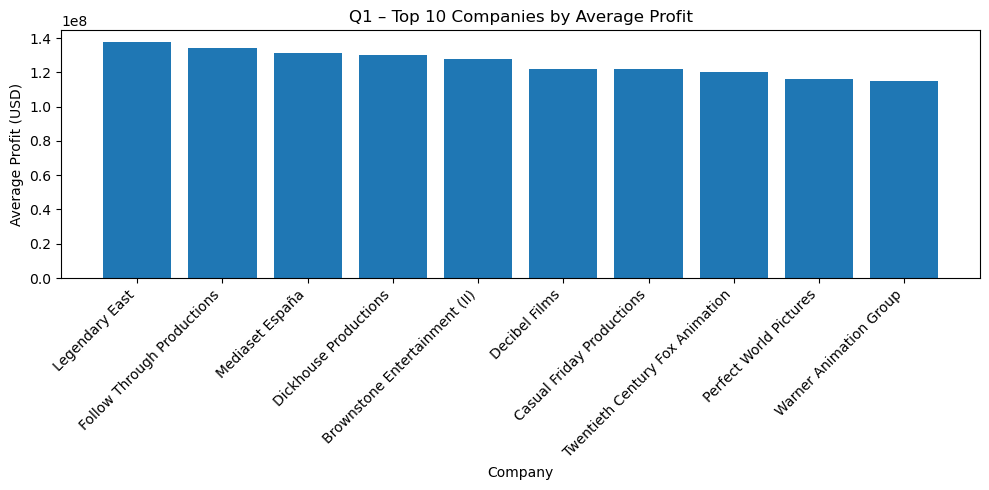

In [43]:
# Cell 13 — Q1: Top 10 Companies by Average Profit

top_companies = (
    df_clean.groupby('company', as_index=False)['profit']
            .mean()
            .sort_values('profit', ascending=False)
            .head(10)
)

print("Top 10 companies by average profit:")
display(top_companies)

plt.figure(figsize=(10, 5))
plt.bar(top_companies['company'], top_companies['profit'])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Company')
plt.ylabel('Average Profit (USD)')
plt.title('Q1 – Top 10 Companies by Average Profit')
plt.tight_layout()
plt.show()


Top 10 countries by average profit:


,country,profit
13,Finland,"69,770,852.62"
28,Lebanon,"59,467,338.43"
37,South Africa,"42,857,879.43"
8,China,"34,778,395.87"
44,United Arab Emirates,"31,169,300.96"
42,Taiwan,"22,718,085.13"
0,Argentina,"22,353,198.88"
39,Spain,"21,110,008.01"
29,Mexico,"14,189,332.62"
36,Russia,"11,749,205.94"


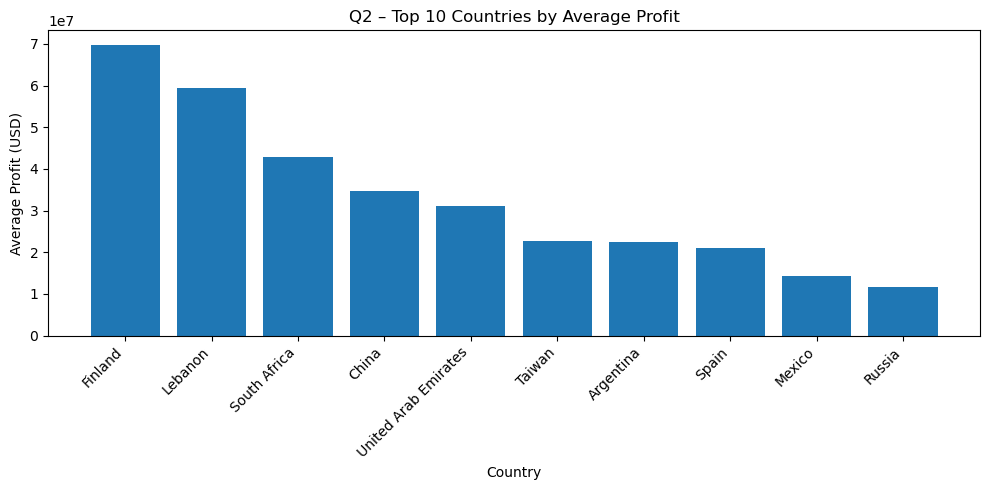

In [44]:
# Cell 14 — Q2: Top 10 Countries by Average Profit

top_countries = (
    df_clean.groupby('country', as_index=False)['profit']
            .mean()
            .sort_values('profit', ascending=False)
            .head(10)
)

print("Top 10 countries by average profit:")
display(top_countries)

plt.figure(figsize=(10, 5))
plt.bar(top_countries['country'], top_countries['profit'])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Country')
plt.ylabel('Average Profit (USD)')
plt.title('Q2 – Top 10 Countries by Average Profit')
plt.tight_layout()
plt.show()


Genre-level averages for adjusted budget, gross, and profit:


,genre,avg_cost,avg_gross,avg_profit
13,Thriller,"25,425,519.00","49,492,860.67","24,067,341.67"
2,Animation,"101,198,220.20","118,403,634.58","17,205,414.38"
9,Horror,"26,334,753.29","39,864,009.81","13,529,256.53"
3,Biography,"42,978,188.05","43,858,473.95","880,285.90"
4,Comedy,"44,448,286.63","44,915,082.39","466,795.76"
8,Fantasy,"40,827,038.65","40,860,130.42","33,091.77"
0,Action,"83,595,200.06","81,139,063.34","-2,456,136.72"
6,Drama,"43,194,558.42","39,778,410.97","-3,416,147.46"
5,Crime,"45,649,195.93","38,954,852.78","-6,694,343.15"
1,Adventure,"69,668,945.11","62,370,920.26","-7,298,024.85"


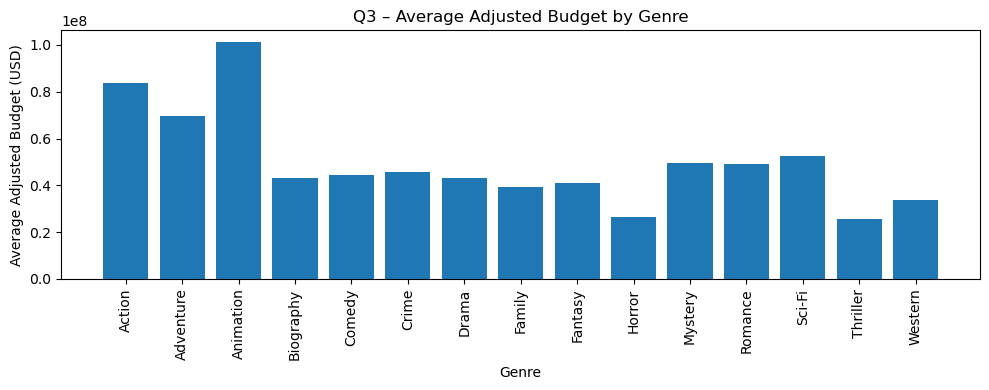

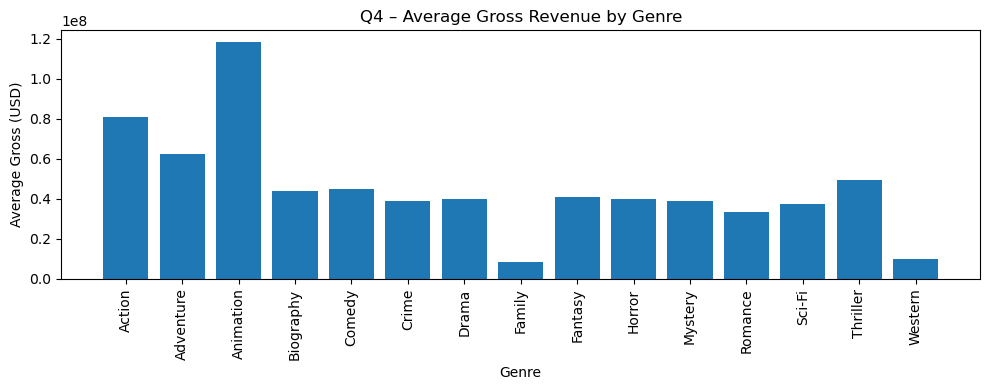

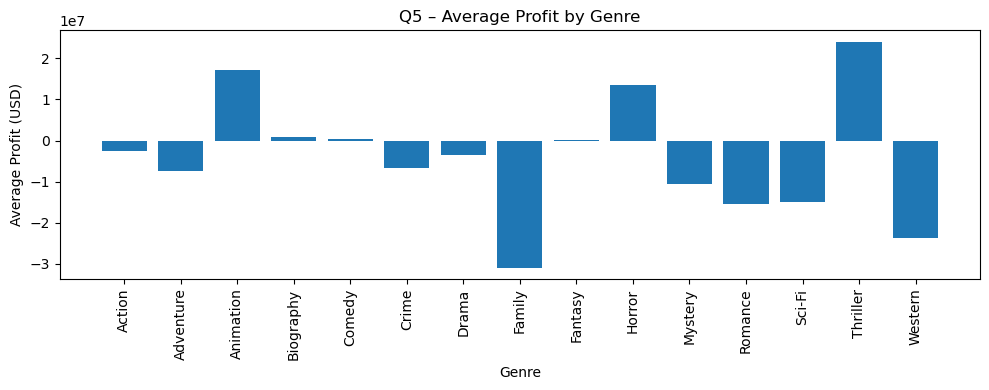

In [45]:
# Cell 15 – Q3–Q5: Genre vs Cost/Gross/Profit

genre_stats = (
    df_clean.groupby('genre')
            .agg(
                avg_cost=('budget_inflation_adjusted', 'mean'),
                avg_gross=('gross', 'mean'),
                avg_profit=('profit', 'mean')
            )
            .reset_index()
)

print("Genre-level averages for adjusted budget, gross, and profit:")
display(genre_stats.sort_values('avg_profit', ascending=False))

# Q3: More expensive to make (Adjusted Budget)
plt.figure(figsize=(10, 4))
plt.bar(genre_stats['genre'], genre_stats['avg_cost'])
plt.xticks(rotation=90)
plt.title('Q3 – Average Adjusted Budget by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Adjusted Budget (USD)')
plt.tight_layout()
plt.show()

# Q4: Higher gross revenues
plt.figure(figsize=(10, 4))
plt.bar(genre_stats['genre'], genre_stats['avg_gross'])
plt.xticks(rotation=90)
plt.title('Q4 – Average Gross Revenue by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Gross (USD)')
plt.tight_layout()
plt.show()

# Q5: Higher profit
plt.figure(figsize=(10, 4))
plt.bar(genre_stats['genre'], genre_stats['avg_profit'])
plt.xticks(rotation=90)
plt.title('Q5 – Average Profit by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Profit (USD)')
plt.tight_layout()
plt.show()


Rating-level averages for adjusted budget, gross, and profit:


,rating,avg_cost,avg_gross,avg_profit
0,Approved,"24,799,395.81","36,565,280.00","11,765,884.19"
1,G,"85,937,093.24","93,978,520.92","8,041,427.68"
5,PG-13,"70,726,373.63","75,295,376.35","4,569,002.72"
3,Not Rated,"11,497,240.62","11,243,732.67","-253,507.95"
4,PG,"69,332,058.02","66,558,941.38","-2,773,116.64"
6,R,"44,053,101.05","40,591,516.85","-3,461,584.21"
8,Unrated,"7,607,662.18","2,458,133.75","-5,149,528.43"
2,NC-17,"21,634,649.18","15,942,256.75","-5,692,392.43"
7,TV-MA,"8,134,233.72","90,777.00","-8,043,456.72"
9,X,"54,035,282.60","17,186,348.00","-36,848,934.60"


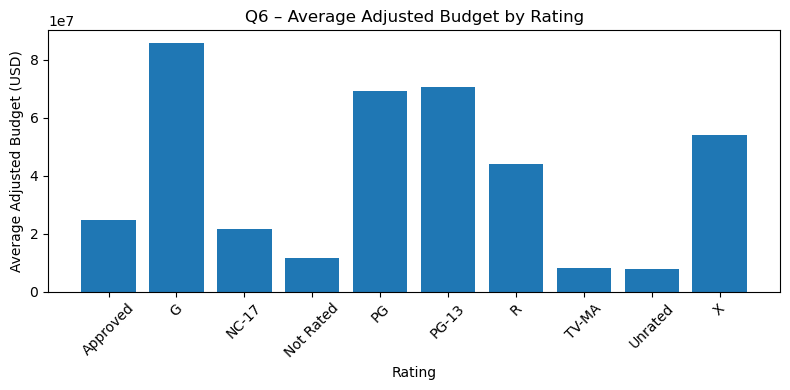

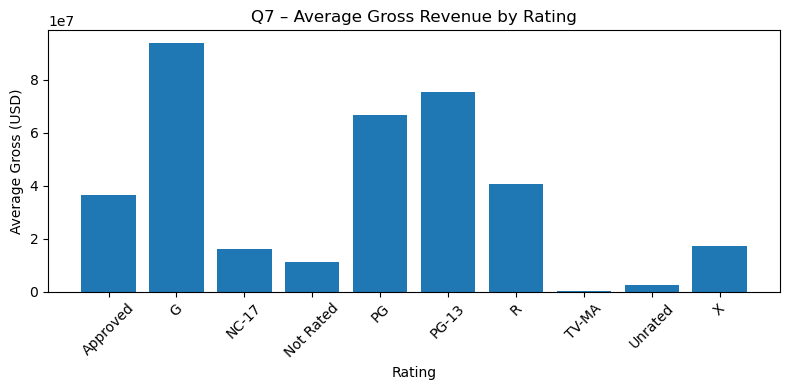

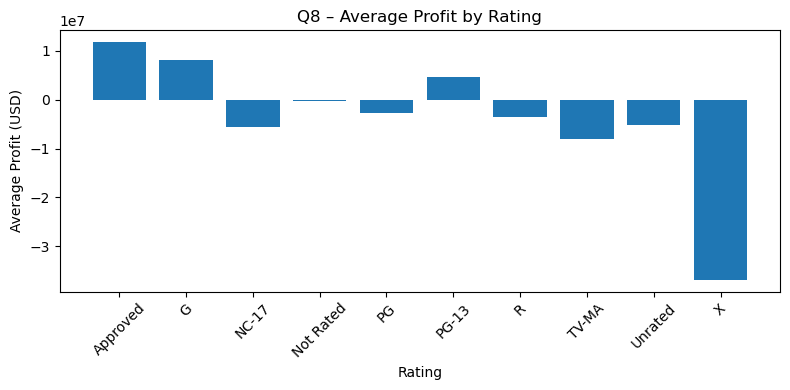

,rating,avg_cost,avg_gross,avg_profit
0,Approved,"24,799,395.81","36,565,280.00","11,765,884.19"
1,G,"85,937,093.24","93,978,520.92","8,041,427.68"
2,NC-17,"21,634,649.18","15,942,256.75","-5,692,392.43"
3,Not Rated,"11,497,240.62","11,243,732.67","-253,507.95"
4,PG,"69,332,058.02","66,558,941.38","-2,773,116.64"
5,PG-13,"70,726,373.63","75,295,376.35","4,569,002.72"
6,R,"44,053,101.05","40,591,516.85","-3,461,584.21"
7,TV-MA,"8,134,233.72","90,777.00","-8,043,456.72"
8,Unrated,"7,607,662.18","2,458,133.75","-5,149,528.43"
9,X,"54,035,282.60","17,186,348.00","-36,848,934.60"


In [46]:
# Cell 16 – Q6–Q8: Rating vs Cost/Gross/Profit

# Aggregate by rating
rating_stats = (
    df_clean.groupby('rating')
            .agg(
                avg_cost=('budget_inflation_adjusted', 'mean'),
                avg_gross=('gross', 'mean'),
                avg_profit=('profit', 'mean')
            )
            .reset_index()
)

print("Rating-level averages for adjusted budget, gross, and profit:")
display(rating_stats.sort_values('avg_profit', ascending=False))

# (Optional) export to CSV for the Word report
# rating_stats.to_csv("Q6_8_rating_cost_gross_profit.csv", index=False)

# Q6 – More expensive to make by rating (Adjusted Budget)
plt.figure(figsize=(8, 4))
plt.bar(rating_stats['rating'], rating_stats['avg_cost'])
plt.xticks(rotation=45)
plt.title('Q6 – Average Adjusted Budget by Rating')
plt.xlabel('Rating')
plt.ylabel('Average Adjusted Budget (USD)')
plt.tight_layout()
plt.show()

# Q7 – Higher gross revenues by rating
plt.figure(figsize=(8, 4))
plt.bar(rating_stats['rating'], rating_stats['avg_gross'])
plt.xticks(rotation=45)
plt.title('Q7 – Average Gross Revenue by Rating')
plt.xlabel('Rating')
plt.ylabel('Average Gross (USD)')
plt.tight_layout()
plt.show()

# Q8 – Higher profit by rating
plt.figure(figsize=(8, 4))
plt.bar(rating_stats['rating'], rating_stats['avg_profit'])
plt.xticks(rotation=45)
plt.title('Q8 – Average Profit by Rating')
plt.xlabel('Rating')
plt.ylabel('Average Profit (USD)')
plt.tight_layout()
plt.show()

rating_stats

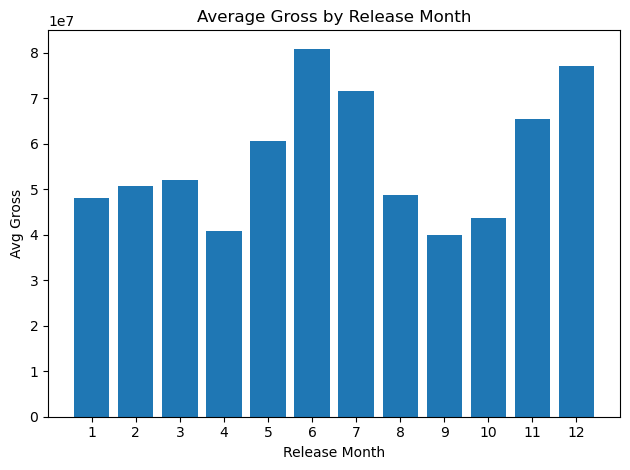

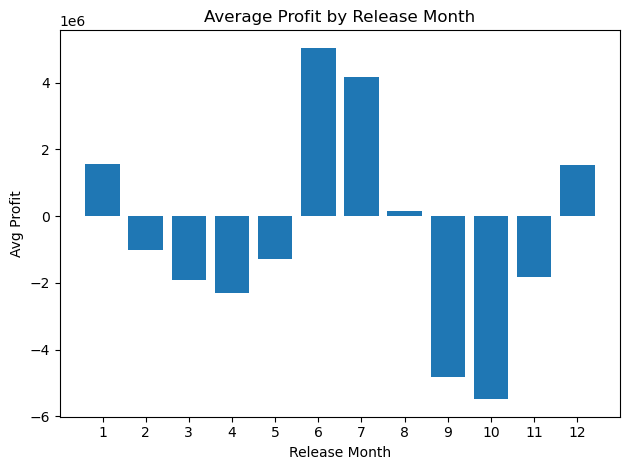

,release_month,avg_gross,avg_profit
0,1,"47,983,421.13","1,561,859.34"
1,2,"50,757,922.74","-1,019,047.08"
2,3,"52,090,125.44","-1,908,488.67"
3,4,"40,856,144.72","-2,313,188.62"
4,5,"60,557,154.66","-1,275,647.73"
5,6,"80,852,099.32","5,038,348.23"
6,7,"71,652,921.68","4,173,387.26"
7,8,"48,615,242.84","143,465.00"
8,9,"40,022,443.72","-4,828,048.61"
9,10,"43,667,293.62","-5,485,786.79"


In [47]:
# Cell 17 — Q9–Q10: Month vs Gross/Profit

month_stats = df_clean.groupby('release_month').agg(
    avg_gross=('gross', 'mean'),
    avg_profit=('profit', 'mean')
).reset_index()

# Q9: Month vs gross
plt.figure()
plt.bar(month_stats['release_month'], month_stats['avg_gross'])
plt.xticks(range(1,13))
plt.title('Average Gross by Release Month')
plt.xlabel('Release Month'); plt.ylabel('Avg Gross')
plt.tight_layout()
plt.show()

# Q10: Month vs profit
plt.figure()
plt.bar(month_stats['release_month'], month_stats['avg_profit'])
plt.xticks(range(1,13))
plt.title('Average Profit by Release Month')
plt.xlabel('Release Month'); plt.ylabel('Avg Profit')
plt.tight_layout()
plt.show()

month_stats


Season-level averages for gross revenue and profit:


,release_season,avg_gross,avg_profit
2,Summer,"64,940,838.52","2,787,888.93"
3,Winter,"58,066,329.07","689,080.39"
1,Spring,"50,347,331.62","-1,882,512.40"
0,Fall,"49,381,915.05","-4,128,300.84"


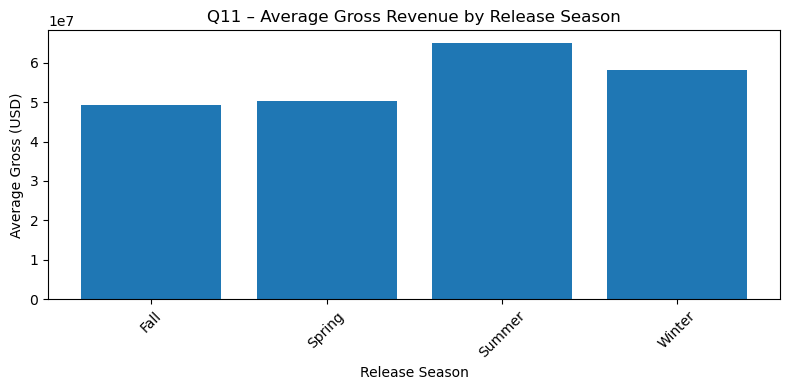

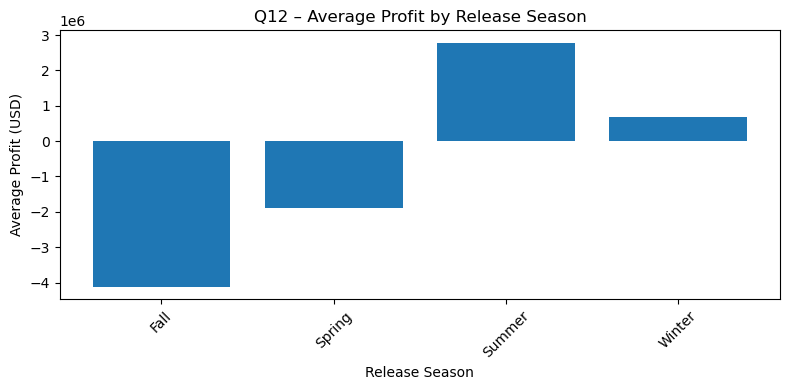

,release_season,avg_gross,avg_profit
0,Fall,"49,381,915.05","-4,128,300.84"
1,Spring,"50,347,331.62","-1,882,512.40"
2,Summer,"64,940,838.52","2,787,888.93"
3,Winter,"58,066,329.07","689,080.39"


In [48]:
# Cell 18 – Q11–Q12: Season vs Gross/Profit

# Aggregate by release season
season_stats = (
    df_clean.groupby('release_season')
            .agg(
                avg_gross=('gross', 'mean'),
                avg_profit=('profit', 'mean')
            )
            .reset_index()
)

print("Season-level averages for gross revenue and profit:")
display(season_stats.sort_values('avg_profit', ascending=False))

# (Optional) export for Word report
# season_stats.to_csv("Q11_12_season_gross_profit.csv", index=False)

# Q11 – Season vs Gross Revenue
plt.figure(figsize=(8, 4))
plt.bar(season_stats['release_season'], season_stats['avg_gross'])
plt.xticks(rotation=45)
plt.title('Q11 – Average Gross Revenue by Release Season')
plt.xlabel('Release Season')
plt.ylabel('Average Gross (USD)')
plt.tight_layout()
plt.show()

# Q12 – Season vs Profit
plt.figure(figsize=(8, 4))
plt.bar(season_stats['release_season'], season_stats['avg_profit'])
plt.xticks(rotation=45)
plt.title('Q12 – Average Profit by Release Season')
plt.xlabel('Release Season')
plt.ylabel('Average Profit (USD)')
plt.tight_layout()
plt.show()

season_stats

Average profit by release day bin:


,release_day_bin,avg_profit
0,1-5,"-829,820.36"
1,6-10,"-544,451.22"
2,11-15,"-189,583.33"
3,16-20,"1,586,438.36"
4,21-25,"-2,033,204.12"
5,26-31,"-2,404,560.70"


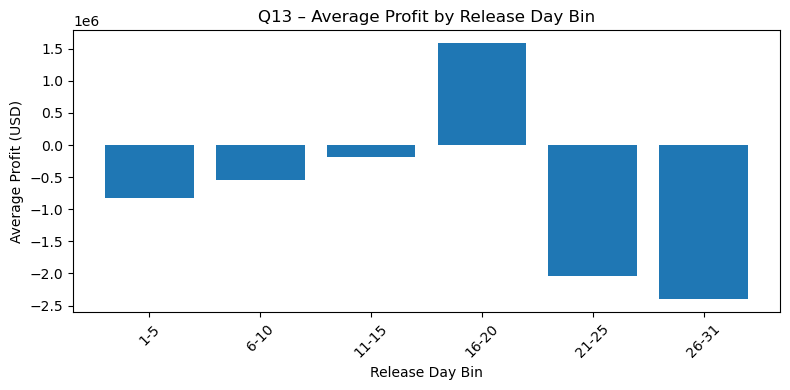

Q14 – Day bins ranked from highest to lowest average profit:


,release_day_bin,avg_profit
3,16-20,"1,586,438.36"
2,11-15,"-189,583.33"
1,6-10,"-544,451.22"
0,1-5,"-829,820.36"
4,21-25,"-2,033,204.12"
5,26-31,"-2,404,560.70"


In [49]:
# Cell 19 – Q13–Q14: Day Bins vs Profit (Highest & Lowest)

# Aggregate by release_day_bin
daybin_stats = (
    df_clean.groupby('release_day_bin')
            .agg(avg_profit=('profit', 'mean'))
            .reset_index()
)

print("Average profit by release day bin:")
display(daybin_stats)

# (Optional) export to CSV for report
# daybin_stats.to_csv("Q13_14_daybins_avg_profit.csv", index=False)

# Q13 – Plot: Average Profit by Release Day Bin
plt.figure(figsize=(8, 4))
plt.bar(daybin_stats['release_day_bin'].astype(str), daybin_stats['avg_profit'])
plt.xticks(rotation=45)
plt.title('Q13 – Average Profit by Release Day Bin')
plt.xlabel('Release Day Bin')
plt.ylabel('Average Profit (USD)')
plt.tight_layout()
plt.show()

# Q14 – Sort bins from highest to lowest profit
daybin_sorted = daybin_stats.sort_values('avg_profit', ascending=False)

print("Q14 – Day bins ranked from highest to lowest average profit:")
display(daybin_sorted)


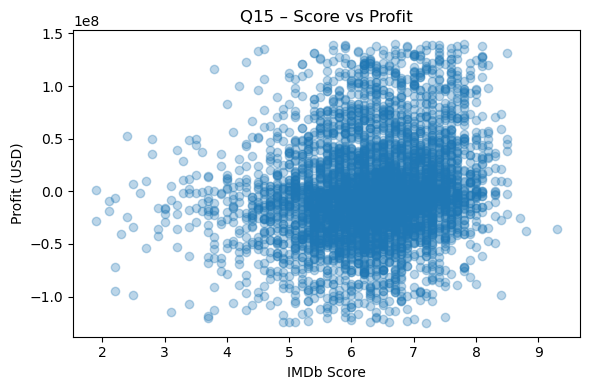

Correlation (score, profit): 0.188 (p = 3.1e-39)  --> LOW correlation


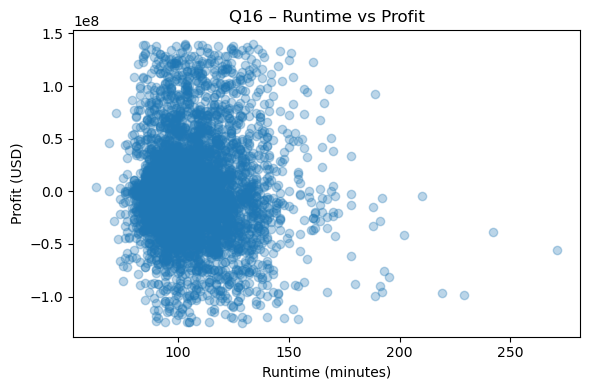

Correlation (runtime, profit): -0.031 (p = 0.0341)  --> VERY LOW / NO correlation


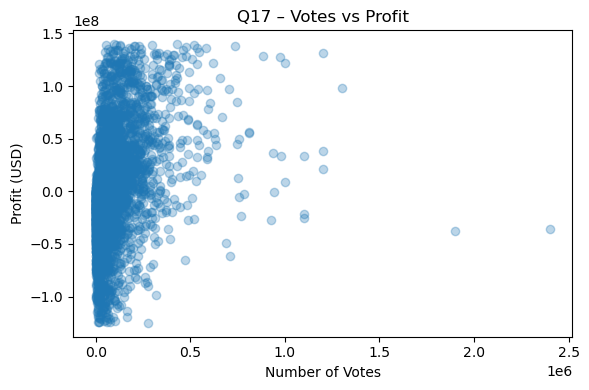

Correlation (votes, profit): 0.368 (p = 9.84e-153)  --> MEDIUM correlation


In [50]:
# Cell 20 – Q15–Q17: Scatterplots & Correlations
from scipy.stats import pearsonr

# -----------------------------------------
# Q15 – Score vs Profit
# -----------------------------------------
plt.figure(figsize=(6, 4))
plt.scatter(df_clean['score'], df_clean['profit'], alpha=0.3)
plt.xlabel('IMDb Score')
plt.ylabel('Profit (USD)')
plt.title('Q15 – Score vs Profit')
plt.tight_layout()
plt.show()

corr_score, p_score = pearsonr(df_clean['score'], df_clean['profit'])
print(f"Correlation (score, profit): {corr_score:.3f} (p = {p_score:.3g})  --> LOW correlation")


# -----------------------------------------
# Q16 – Runtime vs Profit
# -----------------------------------------
plt.figure(figsize=(6, 4))
plt.scatter(df_clean['runtime'], df_clean['profit'], alpha=0.3)
plt.xlabel('Runtime (minutes)')
plt.ylabel('Profit (USD)')
plt.title('Q16 – Runtime vs Profit')
plt.tight_layout()
plt.show()

corr_runtime, p_runtime = pearsonr(df_clean['runtime'], df_clean['profit'])
print(f"Correlation (runtime, profit): {corr_runtime:.3f} (p = {p_runtime:.3g})  --> VERY LOW / NO correlation")


# -----------------------------------------
# Q17 – Votes vs Profit
# -----------------------------------------
plt.figure(figsize=(6, 4))
plt.scatter(df_clean['votes'], df_clean['profit'], alpha=0.3)
plt.xlabel('Number of Votes')
plt.ylabel('Profit (USD)')
plt.title('Q17 – Votes vs Profit')
plt.tight_layout()
plt.show()

corr_votes, p_votes = pearsonr(df_clean['votes'], df_clean['profit'])
print(f"Correlation (votes, profit): {corr_votes:.3f} (p = {p_votes:.3g})  --> MEDIUM correlation")

In [51]:
# Cell 21 — Build Regression Dataset (reg_df)

reg_df = df_clean[[
    'profit',
    'score',
    'votes',
    'years_since_production',
    'movie_name_length',
    'runtime',
    'rating',
    'genre',
    'release_month',
    'release_day_bin'
]].dropna().copy()

reg_df.head()


,profit,score,votes,years_since_production,movie_name_length,runtime,rating,genre,release_month,release_day_bin
0,"-35,168,233.37",5.70,5800,28,10,85.00,PG-13,Comedy,10,1-5
2,"-2,958,476.27",3.90,2300,43,8,85.00,R,Horror,3,11-15
3,"-10,697,439.03",6.80,43000,24,12,108.00,Not Rated,Drama,5,11-15
4,"-13,237,374.11",4.50,1900,31,26,97.00,PG-13,Action,6,1-5
5,"-4,876,793.38",5.80,3500,10,11,96.00,R,Drama,1,11-15


In [52]:
# Cell 22 — Dummy Coding for Regression

reg_df_dum = pd.get_dummies(
    reg_df,
    columns=['rating', 'genre', 'release_month', 'release_day_bin'],
    drop_first=False
)

# REFERENCE CATEGORIES
reference_levels = [
    'rating_Unrated',
    'genre_Biography',
    'release_month_12',
    'release_day_bin_26-31'
]

# DROP ONLY IF column actually exists in data
for ref in reference_levels:
    if ref in reg_df_dum.columns:
        reg_df_dum = reg_df_dum.drop(columns=[ref])

# Build feature matrix
base_cols = [
    'score', 
    'votes',
    'years_since_production',
    'movie_name_length',
    'runtime'
]

dummy_cols = [
    c for c in reg_df_dum.columns
    if c.startswith('rating_')
    or c.startswith('genre_')
    or c.startswith('release_month_')
    or c.startswith('release_day_bin_')
]

X_cols_reg = base_cols + dummy_cols

# Ensure numeric types
X_reg = reg_df_dum[X_cols_reg].apply(pd.to_numeric, errors='coerce')
y_reg = pd.to_numeric(reg_df_dum['profit'], errors='coerce')

valid_rows = (~X_reg.isna().any(axis=1)) & (y_reg.notna())
X_reg = X_reg.loc[valid_rows].astype('float64')
y_reg = y_reg.loc[valid_rows].astype('float64')

X_reg.shape, y_reg.shape
# Cell 22 — Dummy Coding for Regression + X_reg, y_reg

reg_df_dum = pd.get_dummies(
    reg_df,
    columns=['rating', 'genre', 'release_month', 'release_day_bin'],
    drop_first=False
)

# Drop specified reference categories
drop_cols = []
for col in reg_df_dum.columns:
    if col == 'rating_Unrated':
        drop_cols.append(col)
    if col == 'genre_Biography':
        drop_cols.append(col)
    if col == 'release_day_bin_26-31':
        drop_cols.append(col)

reg_df_dum = reg_df_dum.drop(columns=drop_cols, errors='ignore')

# Save for later ML use
reg_dummies = reg_df_dum.copy()

# Base predictors (from hypotheses)
base_cols = [
    'score', 
    'votes',
    'years_since_production',
    'movie_name_length',
    'runtime'
]

dummy_cols = [
    c for c in reg_df_dum.columns
    if c.startswith('rating_')
    or c.startswith('genre_')
    or c.startswith('release_month_')
    or c.startswith('release_day_bin_')
]

X_cols_reg = base_cols + dummy_cols

# Also drop one month dummy as extra reference if present
if 'release_month_12' in X_cols_reg:
    X_cols_reg.remove('release_month_12')

X_reg = reg_df_dum[X_cols_reg].copy()
y_reg = reg_df_dum['profit'].copy()

# Ensure numeric & no NaN
X_reg = X_reg.apply(lambda col: pd.to_numeric(col, errors='coerce'))
y_reg = pd.to_numeric(y_reg, errors='coerce')

valid_rows = (~X_reg.isna().any(axis=1)) & (y_reg.notna())
X_reg = X_reg.loc[valid_rows].astype('float64')
y_reg = y_reg.loc[valid_rows].astype('float64')

X_reg.shape, y_reg.shape


((4769, 44), (4769,))

In [53]:
# Cell 23 — Multicollinearity Check via Correlation Matrix

corr_pred = X_reg.corr().round(2)
print("Correlation matrix among regression predictors:")
corr_pred


Correlation matrix among regression predictors:


,score,votes,years_since_production,movie_name_length,runtime,rating_Approved,rating_G,rating_NC-17,rating_Not Rated,rating_PG,...,release_month_7,release_month_8,release_month_9,release_month_10,release_month_11,release_day_bin_1-5,release_day_bin_6-10,release_day_bin_11-15,release_day_bin_16-20,release_day_bin_21-25
score,1.00,0.43,-0.03,-0.05,0.41,-0.04,0.01,0.02,0.05,-0.11,...,-0.03,-0.06,0.01,0.03,0.04,-0.01,-0.01,0.02,0.02,-0.01
votes,0.43,1.00,-0.19,-0.02,0.26,-0.01,-0.03,-0.00,-0.03,-0.10,...,0.01,-0.04,-0.02,0.03,0.02,-0.02,0.00,0.02,0.03,-0.00
years_since_production,-0.03,-0.19,1.00,0.05,-0.04,0.03,0.04,0.01,-0.04,0.16,...,0.03,-0.01,-0.02,-0.01,0.02,0.00,0.01,0.01,-0.00,-0.01
movie_name_length,-0.05,-0.02,0.05,1.00,-0.05,0.01,0.11,-0.03,-0.02,0.09,...,0.02,0.03,-0.05,0.00,0.02,0.02,-0.02,0.02,-0.00,0.00
runtime,0.41,0.26,-0.04,-0.05,1.00,0.01,-0.15,-0.01,0.04,-0.10,...,-0.04,-0.07,-0.01,0.04,-0.00,-0.04,0.01,0.02,0.00,0.03
rating_Approved,-0.04,-0.01,0.03,0.01,0.01,1.00,-0.00,-0.00,-0.00,-0.01,...,0.05,-0.00,-0.00,-0.00,-0.00,-0.01,-0.01,-0.01,-0.01,0.03
rating_G,0.01,-0.03,0.04,0.11,-0.15,-0.00,1.00,-0.01,-0.01,-0.06,...,0.04,-0.01,-0.04,-0.04,0.09,-0.00,-0.02,0.00,0.02,0.00
rating_NC-17,0.02,-0.00,0.01,-0.03,-0.01,-0.00,-0.01,1.00,-0.00,-0.02,...,-0.01,-0.02,0.04,0.01,-0.02,-0.01,-0.02,0.01,-0.00,0.02
rating_Not Rated,0.05,-0.03,-0.04,-0.02,0.04,-0.00,-0.01,-0.00,1.00,-0.04,...,-0.00,-0.02,0.01,-0.00,0.02,-0.00,-0.02,0.02,0.01,-0.01
rating_PG,-0.11,-0.10,0.16,0.09,-0.10,-0.01,-0.06,-0.02,-0.04,1.00,...,0.04,0.00,-0.05,-0.03,0.01,-0.01,0.01,-0.02,0.04,0.01


# Part C: Multiple Linear Regression (Unstandardized & Standardized)

In [54]:
# Cell 24 – Regression Models (Unstandardized & Standardized)

# ------------------------------------------------
# 1) UNSTANDARDIZED MULTIPLE LINEAR REGRESSION
# ------------------------------------------------

# Add constant term
X_reg_const = sm.add_constant(X_reg)

# Fit OLS model with unstandardized predictors
model_unstd = sm.OLS(y_reg, X_reg_const).fit()

print("=== Unstandardized Regression Summary: Coefficients Table ===")
display(model_unstd.summary().tables[1])

print(f"\nR-squared:      {model_unstd.rsquared:.3f}")
print(f"Adj R-squared:  {model_unstd.rsquared_adj:.3f}")
print(f"Observations:   {int(model_unstd.nobs)}")

# ------------------------------------------------
# 2) STANDARDIZED MULTIPLE LINEAR REGRESSION
#    (standardize ONLY X, NOT y)
# ------------------------------------------------

scaler_reg = StandardScaler()
X_reg_scaled_array = scaler_reg.fit_transform(X_reg)

# Put back into DataFrame to keep column names
X_reg_scaled = pd.DataFrame(X_reg_scaled_array,
                            columns=X_reg.columns,
                            index=X_reg.index)

# Add constant term to standardized predictors
X_reg_scaled_const = sm.add_constant(X_reg_scaled)

# Fit OLS model with standardized predictors
model_std = sm.OLS(y_reg, X_reg_scaled_const).fit()

print("\n=== Standardized Regression (for Std. Betas only) ===")
print(f"R-squared (should match):      {model_std.rsquared:.3f}")
print(f"Adj R-squared (should match): {model_std.rsquared_adj:.3f}\n")

# ------------------------------------------------
# 3) BUILD RESULTS TABLE:
#    Unstandardized beta, Standardized beta, p-value, Hypothesis supported?
# ------------------------------------------------

# Build a combined coefficients table
results_df = pd.DataFrame({
    "Variable": X_reg_const.columns,                  # ['const', predictor names]
    "Unstandardized_Beta": model_unstd.params.values,
    "Standardized_Beta":   model_std.params.values,
    "p_value":             model_unstd.pvalues.values
})

# Nicely formatted p-values for the Word report
def format_p(p):
    return "p < .001" if p < 0.001 else f"p = {p:.3f}"

results_df["p_value_formatted"] = results_df["p_value"].apply(format_p)

# Hypothesis supported? (Yes if p < .05)
results_df["Hypothesis_Supported"] = results_df["p_value"].apply(
    lambda p: "Yes" if p < 0.05 else "No"
)

# Round betas & numeric p-values as required
results_df["Unstandardized_Beta"] = results_df["Unstandardized_Beta"].round(2)
results_df["Standardized_Beta"]   = results_df["Standardized_Beta"].round(2)
results_df["p_value"]             = results_df["p_value"].round(3)

# Reorder columns to match project template
results_df = results_df[
    ["Variable",
     "Unstandardized_Beta",
     "Standardized_Beta",
     "p_value",
     "p_value_formatted",
     "Hypothesis_Supported"]
]

print("=== Part C Regression Results Table (copy into Word) ===")
display(results_df)


# ------------------------------------------------
# 4) Identify TOP 2 strongest standardized effects (for write-up)
# ------------------------------------------------

coef_no_const = results_df[results_df["Variable"] != "const"]

top2 = coef_no_const.reindex(
    coef_no_const["Standardized_Beta"].abs().sort_values(ascending=False).head(2).index
)

print("\nTop 2 strongest standardized effects on profit (by |Std_Beta|):")
for _, row in top2.iterrows():
    direction = "positive" if row["Standardized_Beta"] > 0 else "negative"
    print(f" - {row['Variable']}: Std_Beta = {row['Standardized_Beta']:.2f} ({direction} effect)")


=== Unstandardized Regression Summary: Coefficients Table ===


,coef,std err,t,P>|t|,[0.025,0.975]
const,7.43e+06,1.26e+07,0.589,0.556,-1.73e+07,3.21e+07
score,7.232e+06,7.93e+05,9.122,0.000,5.68e+06,8.79e+06
votes,119.8734,5.735,20.904,0.000,108.631,131.116
years_since_production,-1.241e+06,6.07e+04,-20.451,0.000,-1.36e+06,-1.12e+06
movie_name_length,1.767e+05,8.03e+04,2.201,0.028,1.93e+04,3.34e+05
runtime,-3.909e+05,4.2e+04,-9.314,0.000,-4.73e+05,-3.09e+05
rating_Approved,8.026e+07,4.24e+07,1.895,0.058,-2.79e+06,1.63e+08
rating_G,1.344e+07,1.15e+07,1.166,0.244,-9.17e+06,3.61e+07
rating_NC-17,2.712e+06,1.56e+07,0.173,0.862,-2.8e+07,3.34e+07
rating_Not Rated,3.071e+06,1.2e+07,0.255,0.799,-2.05e+07,2.67e+07



R-squared:      0.253
Adj R-squared:  0.246
Observations:   4769

=== Standardized Regression (for Std. Betas only) ===
R-squared (should match):      0.253
Adj R-squared (should match): 0.246

=== Part C Regression Results Table (copy into Word) ===


,Variable,Unstandardized_Beta,Standardized_Beta,p_value,p_value_formatted,Hypothesis_Supported
0,const,"7,430,013.31","-722,208.02",0.56,p = 0.556,No
1,score,"7,231,879.88","6,827,421.50",0.00,p < .001,Yes
2,votes,119.87,"14,493,622.52",0.00,p < .001,Yes
3,years_since_production,"-1,240,934.99","-13,005,918.48",0.00,p < .001,Yes
4,movie_name_length,"176,710.19","1,327,698.10",0.03,p = 0.028,Yes
5,runtime,"-390,944.14","-6,641,093.25",0.00,p < .001,Yes
6,rating_Approved,"80,263,332.30","1,162,138.76",0.06,p = 0.058,No
7,rating_G,"13,443,286.33","1,788,913.87",0.24,p = 0.244,No
8,rating_NC-17,"2,712,141.66","135,875.84",0.86,p = 0.862,No
9,rating_Not Rated,"3,071,131.76","290,303.46",0.80,p = 0.799,No



Top 2 strongest standardized effects on profit (by |Std_Beta|):
 - votes: Std_Beta = 14493622.52 (positive effect)
 - years_since_production: Std_Beta = -13005918.48 (negative effect)


# Part D: Predictive Modeling (Tree + Neural Network)

In [55]:
# Cell 25 — Prepare Data for Predictive Modeling (X_ml, y_ml, Train/Test Split)

# Using the SAME predictors as in Part C regression
# (X_reg and y_reg were created in Cell 22)
X_ml = X_reg.copy()
y_ml = y_reg.copy()

# 70/30 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_ml, y_ml,
    test_size=0.30,
    random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)


Train shape: (3338, 44)
Test shape : (1431, 44)


In [56]:
# Cell 26 — Part D: Decision Tree Models (Test R² & RMSE)

dt_results = []

max_depth_values = [3, 5, 7, 9, 12]
min_leaf_values = [5, 10, 20]

best_dt = None
best_dt_r2 = -np.inf
best_dt_rmse = np.inf

for depth in max_depth_values:
    for leaf in min_leaf_values:
        dt = DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=42
        )
        dt.fit(X_train, y_train)
        y_pred_test = dt.predict(X_test)

        r2 = r2_score(y_test, y_pred_test)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

        dt_results.append({
            "max_depth": depth,
            "min_samples_leaf": leaf,
            "R2_test": r2,
            "RMSE_test": rmse
        })

        # keep the best tree (higher R², if tie then lower RMSE)
        if (r2 > best_dt_r2) or (r2 == best_dt_r2 and rmse < best_dt_rmse):
            best_dt = dt
            best_dt_r2 = r2
            best_dt_rmse = rmse

dt_results_df = pd.DataFrame(dt_results).sort_values(
    by=["R2_test", "RMSE_test"],
    ascending=[False, True]
)

print("Decision Tree models sorted by test performance:")
display(dt_results_df.head(10))

print("Best Decision Tree — R² (test):", round(best_dt_r2, 3))
print("Best Decision Tree — RMSE (test):", round(best_dt_rmse, 2))

Decision Tree models sorted by test performance:


,max_depth,min_samples_leaf,R2_test,RMSE_test
5,5,20,0.27,"41,037,245.98"
8,7,20,0.27,"41,211,619.71"
3,5,5,0.26,"41,419,202.78"
4,5,10,0.25,"41,549,370.17"
11,9,20,0.25,"41,691,629.77"
14,12,20,0.25,"41,757,779.77"
0,3,5,0.24,"41,823,687.42"
1,3,10,0.24,"41,823,687.42"
2,3,20,0.24,"41,823,687.42"
7,7,10,0.22,"42,568,314.05"


Best Decision Tree — R² (test): 0.273
Best Decision Tree — RMSE (test): 41037245.98


In [57]:
# Cell 27 — Part D: Neural Network Models (MLPRegressor)

# Scale inputs for neural network
scaler_nn = StandardScaler()
X_train_scaled = scaler_nn.fit_transform(X_train)
X_test_scaled = scaler_nn.transform(X_test)

nn_results = []

best_nn = None
best_nn_r2 = -np.inf
best_nn_rmse = np.inf

hidden_options = [(32,), (64,), (32, 16)]
alpha_options = [0.0001, 0.001]

for hidden in hidden_options:
    for alpha in alpha_options:
        nn = MLPRegressor(
            hidden_layer_sizes=hidden,
            activation='relu',
            solver='adam',
            alpha=alpha,
            random_state=42,
            max_iter=500
        )

        nn.fit(X_train_scaled, y_train)
        y_pred_test = nn.predict(X_test_scaled)

        r2 = r2_score(y_test, y_pred_test)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

        nn_results.append({
            "hidden_layers": hidden,
            "alpha": alpha,
            "R2_test": r2,
            "RMSE_test": rmse
        })

        if (r2 > best_nn_r2) or (r2 == best_nn_r2 and rmse < best_nn_rmse):
            best_nn = nn
            best_nn_r2 = r2
            best_nn_rmse = rmse

nn_results_df = pd.DataFrame(nn_results).sort_values(
    by=["R2_test", "RMSE_test"],
    ascending=[False, True]
)

print("Neural Network models sorted by test performance:")
display(nn_results_df)

print("Best Neural Net — R² (test):", round(best_nn_r2, 3))
print("Best Neural Net — RMSE (test):", round(best_nn_rmse, 2))


Neural Network models sorted by test performance:


,hidden_layers,alpha,R2_test,RMSE_test
5,"(32, 16)",0.00,0.01,"47,813,241.74"
4,"(32, 16)",0.00,0.01,"47,813,241.74"
2,"(64,)",0.00,-0.00,"48,144,008.41"
3,"(64,)",0.00,-0.00,"48,144,008.41"
0,"(32,)",0.00,-0.00,"48,146,621.72"
1,"(32,)",0.00,-0.00,"48,146,621.72"


Best Neural Net — R² (test): 0.013
Best Neural Net — RMSE (test): 47813241.74


In [58]:
# Cell 28 — Part D: Model Comparison & Predictions for New Movies

# 1) Compare performance of best DT vs best NN
comparison_df = pd.DataFrame([
    {"Model": "Decision Tree", "R2_test": best_dt_r2, "RMSE_test": best_dt_rmse},
    {"Model": "Neural Network", "R2_test": best_nn_r2, "RMSE_test": best_nn_rmse}
])

print("Part D — Test Set Performance Comparison:")
display(comparison_df)

# Pick best model (higher R², if similar you can also look at RMSE)
if best_nn_r2 > best_dt_r2:
    best_model_name = "Neural Network"
    best_model = best_nn
    use_scaler_for_best = True
else:
    best_model_name = "Decision Tree"
    best_model = best_dt
    use_scaler_for_best = False

print("Chosen model for predictions:", best_model_name)

# 2) Build DataFrame for the three new movies
new_movies_raw = pd.DataFrame({
    "name": ["Gorga", "King Wolf", "Hellish Gray"],
    "rating": ["R", "R", "PG"],
    "genre": ["Drama", "Drama", "Comedy"],
    "year": [2025, 2025, 2025],
    "released": ["June 1, 2026", "March 1, 2027", "July 1, 2026"],
    "director": ["Alex Bandit", "Alex Bandit", "Alex Bandit"],
    "writer": ["Frida Nour", "Dilip Sherman", "Franco Toro"],
    "star": ["Marcello Mastroianni", "Paul Michael Glaser", "David N. Haynes"],
    "country": ["United States", "United States", "United States"],
    "budget": [130000000, 250000000, 310000000],  # NOT used as predictor
    "company": ["Universal Pictures", "Universal Pictures", "Universal Pictures"],
    "runtime": [250, 135, 108]
})

# 3) Recreate engineered variables consistently with Part A

new_movies = new_movies_raw.copy()

# release_date and components
new_movies["release_date"] = pd.to_datetime(new_movies["released"], errors="coerce")
new_movies["release_year"] = new_movies["release_date"].dt.year
new_movies["release_month"] = new_movies["release_date"].dt.month
new_movies["release_day"] = new_movies["release_date"].dt.day

# season function should already exist from Part A
new_movies["release_season"] = new_movies["release_month"].apply(month_to_season)

# day bins (same bins you used in Part A)
bins = [0, 5, 10, 15, 20, 25, 31]
labels = ["1-5", "6-10", "11-15", "16-20", "21-25", "26-31"]
new_movies["release_day_bin"] = pd.cut(
    new_movies["release_day"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# movie_name_length
new_movies["movie_name_length"] = new_movies["name"].str.len()

# years_since_production (based on release_year, same as in Part A)
current_year = pd.Timestamp.today().year
new_movies["years_since_production"] = current_year - new_movies["release_year"]

# 4) Fill score & votes with dataset averages (per instructions)
avg_score = df_clean["score"].mean()
avg_votes = df_clean["votes"].mean()

new_movies["score"] = avg_score
new_movies["votes"] = avg_votes

# 5) Keep ONLY the inputs used in X_reg (no budget / gross)
new_reg = new_movies[[
    "score",
    "votes",
    "years_since_production",
    "movie_name_length",
    "runtime",
    "rating",
    "genre",
    "release_month",
    "release_day_bin"
]].copy()

# 6) Dummy code with the same categorical variables as in reg_dummies
new_dummies = pd.get_dummies(
    new_reg,
    columns=["rating", "genre", "release_month", "release_day_bin"],
    drop_first=False
)

# Align columns to X_reg: add missing columns with 0, then reorder
for col in X_reg.columns:
    if col not in new_dummies.columns:
        new_dummies[col] = 0

new_dummies = new_dummies[X_reg.columns]

# 7) Scale if using NN, otherwise keep as is
if use_scaler_for_best:
    new_features = scaler_nn.transform(new_dummies)
else:
    new_features = new_dummies.values

# 8) Predict profit
new_profit_pred = best_model.predict(new_features)

pred_df = pd.DataFrame({
    "Movie": new_movies_raw["name"],
    "Predicted_Profit": new_profit_pred
})

print("Predicted profitability for the three new movies:")
display(pred_df)

Part D — Test Set Performance Comparison:


,Model,R2_test,RMSE_test
0,Decision Tree,0.27,"41,037,245.98"
1,Neural Network,0.01,"47,813,241.74"


Chosen model for predictions: Decision Tree
Predicted profitability for the three new movies:


,Movie,Predicted_Profit
0,Gorga,"44,266,022.70"
1,King Wolf,"44,266,022.70"
2,Hellish Gray,"44,266,022.70"
